**Cell 1: Install Required Libraries**

In [ ]:
!pip install -q ultralytics opencv-python-headless \
    supervision numpy matplotlib pandas

**Cell 2: Import Required Libraries**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from ultralytics import YOLO
from collections import defaultdict

import os
import urllib.request

print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!


**Cell 3: Download Input Video**

In [ ]:
VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"

INPUT_DIR = "/content/input"
OUTPUT_DIR = "/content/output"

os.makedirs(INPUT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

VIDEO_PATH = os.path.join(INPUT_DIR, "people-walking.mp4")

urllib.request.urlretrieve(VIDEO_URL, VIDEO_PATH)

print("Video downloaded successfully!")
print("Video path:", VIDEO_PATH)

Video downloaded successfully!
Video path: /content/input/people-walking.mp4


**Cell 4: Inspect Video Properties**

In [ ]:
cap = cv2.VideoCapture(VIDEO_PATH)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

duration = total_frames / fps if fps > 0 else 0

print("Video Information")
print("-------------------------")
print("Resolution:", width, "x", height)
print("FPS:", fps)
print("Total Frames:", total_frames)
print("Duration:", round(duration, 2), "seconds")

cap.release()

Video Information
-------------------------
Resolution: 1920 x 1080
FPS: 25.0
Total Frames: 341
Duration: 13.64 seconds


**Cell 5: Check GPU Availability**

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0

    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

else:
    DEVICE = "cpu"
    print("GPU not available. Using CPU.")

print("Selected Device:", DEVICE)

PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Name: Tesla T4
CUDA Version: 13.0
GPU Memory: 14.56 GB
Selected Device: 0


**Cell 6: Load YOLO11n Pre-trained Model**

In [ ]:
from ultralytics import YOLO

MODEL_NAME = "yolo11s.pt"

model = YOLO(MODEL_NAME)

# Move model to GPU
model.to(DEVICE)

print("YOLO model loaded successfully!")
print("Model:", MODEL_NAME)
print("Device:", DEVICE)

YOLO model loaded successfully!
Model: yolo11s.pt
Device: 0


**Cell 7: YOLO People Detection**

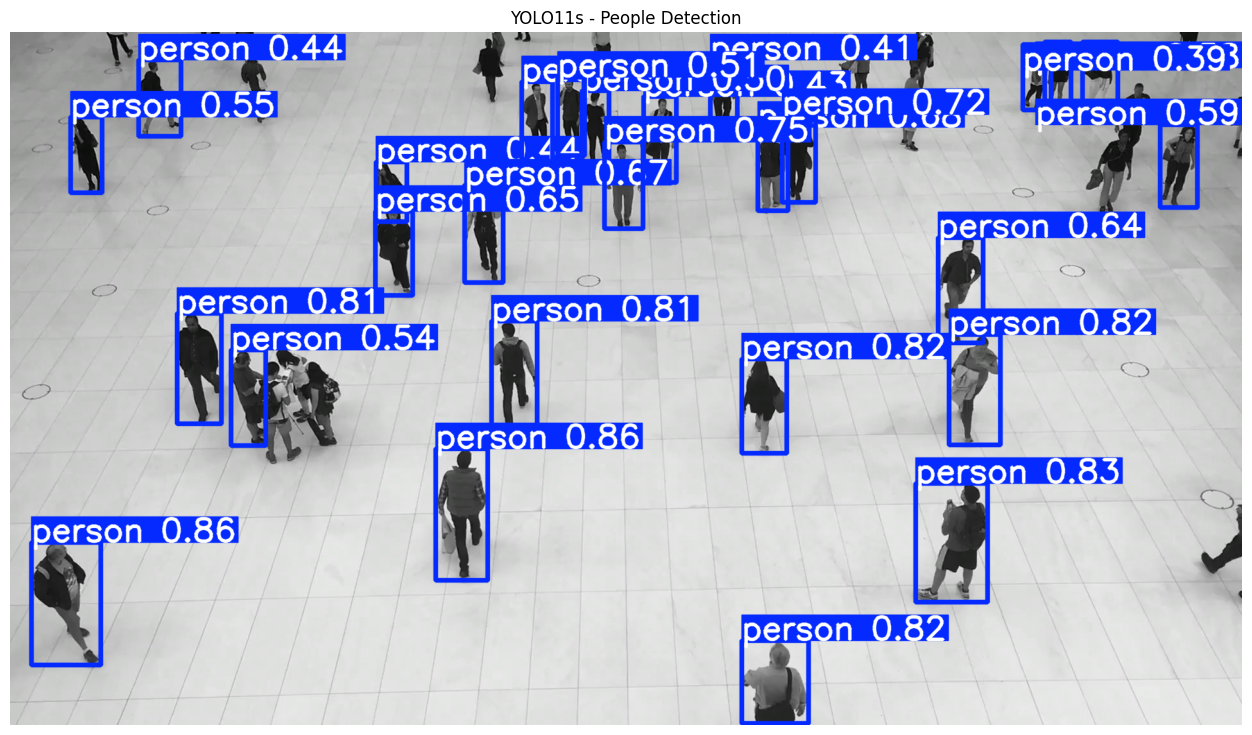

Detected people: 27


In [ ]:
cap = cv2.VideoCapture(VIDEO_PATH)

ret, frame = cap.read()
cap.release()

if ret:
    results = model.predict(
        source=frame,
        classes=[0],
        conf=0.35,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )

    annotated_frame = results[0].plot()

    # Convert BGR to RGB
    annotated_rgb = cv2.cvtColor(
        annotated_frame, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(16, 9))
    plt.imshow(annotated_rgb)
    plt.title("YOLO11s - People Detection")
    plt.axis("off")
    plt.show()

    print("Detected people:", len(results[0].boxes))

else:
    print("Unable to read video frame.")

**Cell 8: GPU Inference Benchmark**

In [ ]:
import time

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.time()

results = model.predict(
    source=frame,
    classes=[0],
    conf=0.35,
    imgsz=640,
    device=DEVICE,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

inference_time = (time.time() - start_time) * 1000

print("Inference Performance")
print("----------------------------")
print(f"Inference Time: {inference_time:.2f} ms")
print(f"Detected People: {len(results[0].boxes)}")
print("Device:", DEVICE)

Inference Performance
----------------------------
Inference Time: 21.42 ms
Detected People: 27
Device: 0


**Cell 9: GPU Status**

In [ ]:
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

    print(
        "Allocated GPU Memory:",
        round(torch.cuda.memory_allocated() / 1024**2, 2),
        "MB"
    )

    print(
        "Reserved GPU Memory:",
        round(torch.cuda.memory_reserved() / 1024**2, 2),
        "MB"
    )
else:
    print("CUDA GPU is not available.")

Tesla T4
Allocated GPU Memory: 145.98 MB
Reserved GPU Memory: 190.0 MB


**Cell 10: Initialize ByteTrack Tracking**

In [ ]:
cap = cv2.VideoCapture(VIDEO_PATH)

tracking_frame = None
tracking_ids = set()

frame_count = 0
PREVIEW_FRAMES = 100

while frame_count < PREVIEW_FRAMES:

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.35,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )

    result = results[0]

    # Extract tracking IDs
    if result.boxes.id is not None:

        ids = result.boxes.id.cpu().numpy().astype(int)

        tracking_ids.update(ids.tolist())

    # Save a sample tracking frame
    if frame_count == 75:
        tracking_frame = result.plot()

    frame_count += 1

cap.release()

print("ByteTrack initialized successfully!")
print("Frames processed:", frame_count)
print("Unique IDs observed:", sorted(tracking_ids))
print("Total unique IDs:", len(tracking_ids))

ByteTrack initialized successfully!
Frames processed: 100
Unique IDs observed: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 34, 35, 43, 44, 46, 47, 48, 49, 50, 52, 55, 57, 59, 60, 61, 62, 65, 66, 71, 72, 73, 74, 75, 76]
Total unique IDs: 55


**Cell 11: Display ByteTrack Results**

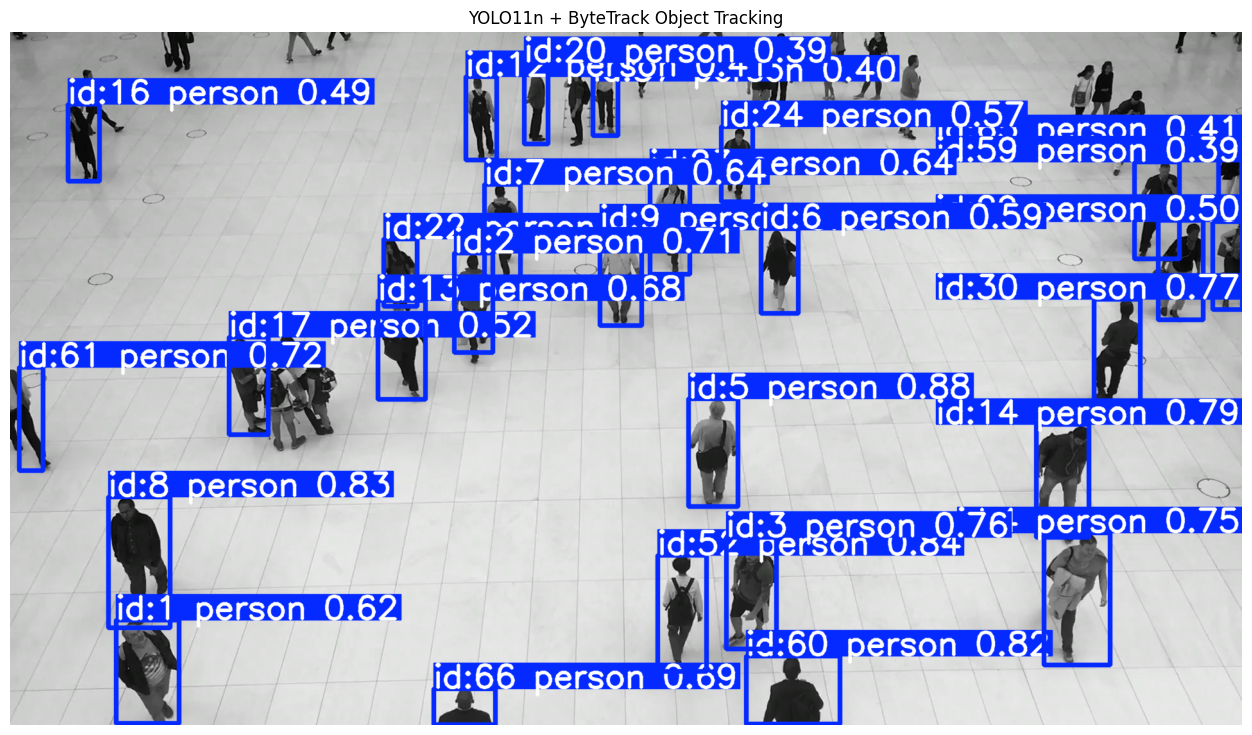

In [ ]:
if tracking_frame is not None:

    tracking_rgb = cv2.cvtColor(
        tracking_frame,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(16, 9))
    plt.imshow(tracking_rgb)
    plt.title("YOLO11n + ByteTrack Object Tracking")
    plt.axis("off")
    plt.show()

else:
    print("Tracking preview frame unavailable.")

**Cell 12: Initialize Tracking and Counting Variables**

In [ ]:
track_history = defaultdict(lambda: {
    "previous_y": None,
    "current_y": None,
    "counted": False
})

# People flow counters
IN_COUNT = 0
OUT_COUNT = 0

# Counting line coordinates
UPPER_LINE_Y = 360
LOWER_LINE_Y = 720

# Heatmap accumulator
heatmap = np.zeros(
    (height, width),
    dtype=np.float32
)

print("Tracking history initialized.")
print("Upper counting line:", UPPER_LINE_Y)
print("Lower counting line:", LOWER_LINE_Y)
print("Heatmap dimensions:", heatmap.shape)

Tracking history initialized.
Upper counting line: 360
Lower counting line: 720
Heatmap dimensions: (1080, 1920)


**Cell 13: Counting Line Visualization**

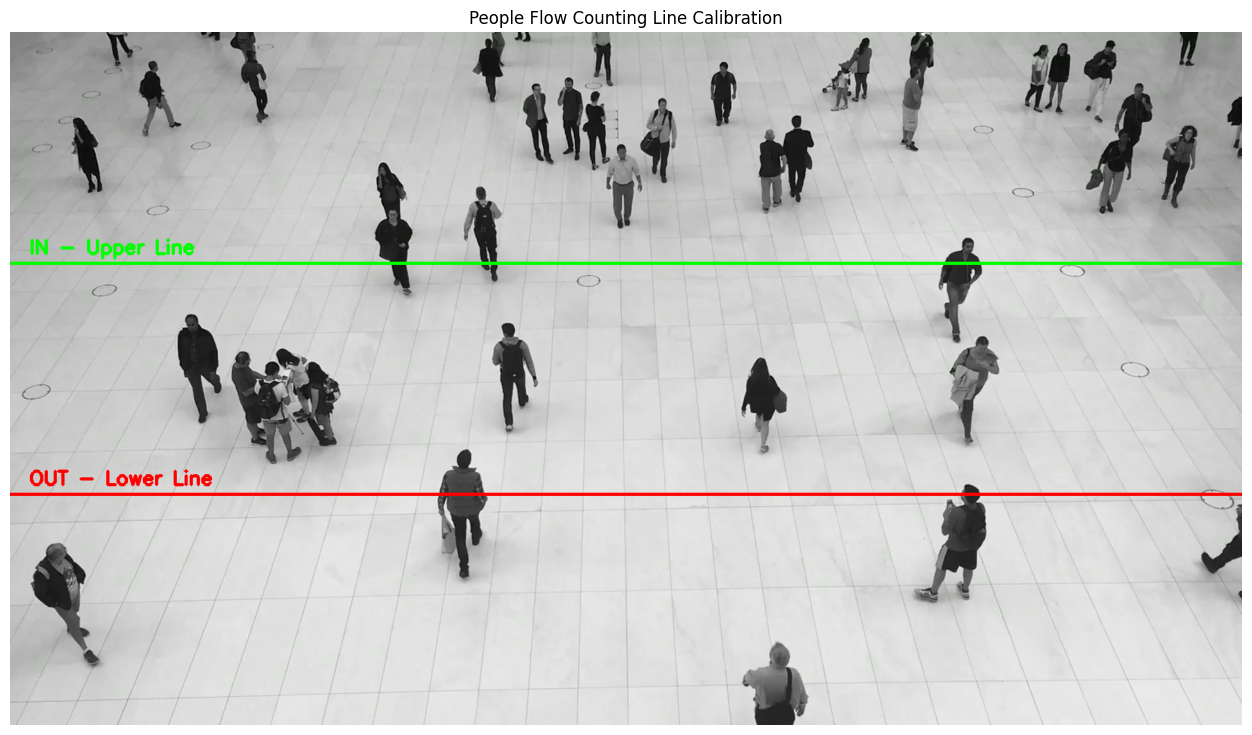

In [ ]:
cap = cv2.VideoCapture(VIDEO_PATH)

ret, frame = cap.read()
cap.release()

if ret:

    line_preview = frame.copy()

    # Upper line: IN
    cv2.line(
        line_preview,
        (0, UPPER_LINE_Y),
        (width, UPPER_LINE_Y),
        (0, 255, 0),
        4
    )

    # Lower line: OUT
    cv2.line(
        line_preview,
        (0, LOWER_LINE_Y),
        (width, LOWER_LINE_Y),
        (0, 0, 255),
        4
    )

    # Line labels
    cv2.putText(
        line_preview,
        "IN - Upper Line",
        (30, UPPER_LINE_Y - 15),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        3
    )

    cv2.putText(
        line_preview,
        "OUT - Lower Line",
        (30, LOWER_LINE_Y - 15),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        3
    )

    plt.figure(figsize=(16, 9))
    plt.imshow(cv2.cvtColor(line_preview, cv2.COLOR_BGR2RGB))
    plt.title("People Flow Counting Line Calibration")
    plt.axis("off")
    plt.show()

else:
    print("Unable to load video frame.")

**Cell 14: Initialize Complete People Flow Pipeline**

In [ ]:
from collections import defaultdict
from tqdm.auto import tqdm

# Load a fresh YOLO model to reset previous tracking state
tracking_model = YOLO(MODEL_NAME)
tracking_model.to(DEVICE)

# Tracking history
track_history = {}

# Prevent duplicate counting
counted_ids = set()

# People flow counters
IN_COUNT = 0
OUT_COUNT = 0

# Event records
counting_events = []

# Heatmap accumulator
heatmap = np.zeros((height, width), dtype=np.float32)

# Output video
OUTPUT_VIDEO = os.path.join(
    OUTPUT_DIR, "people_flow_output.mp4"
)

# Heatmap output paths
HEATMAP_PATH = os.path.join(
    OUTPUT_DIR, "people_heatmap.png"
)

HEATMAP_OVERLAY_PATH = os.path.join(
    OUTPUT_DIR, "people_heatmap_overlay.png"
)

# Video writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

out = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    fps,
    (width, height)
)

print("Pipeline initialized successfully!")
print("Processing device:", DEVICE)
print("Counting lines:", UPPER_LINE_Y, LOWER_LINE_Y)
print("Output video:", OUTPUT_VIDEO)

Pipeline initialized successfully!
Processing device: 0
Counting lines: 360 720
Output video: /content/output/people_flow_output.mp4


**Cell 15: Full Video Processing**

In [ ]:
# YOLO11n + ByteTrack + IN/OUT Counting + Heatmap

cap = cv2.VideoCapture(VIDEO_PATH)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Reset counters and tracking history
IN_COUNT = 0
OUT_COUNT = 0

counted_ids = set()
track_history = {}
counting_events = []

heatmap = np.zeros((height, width), dtype=np.float32)

processed_frames = 0

# Process every frame
for frame_idx in tqdm(range(total_frames), desc="Processing Video"):

    ret, frame = cap.read()

    if not ret:
        break

    # YOLO + ByteTrack detection
    results = tracking_model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[0],
        conf=0.35,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )

    result = results[0]

    # Draw counting lines
    cv2.line(
        frame,
        (0, UPPER_LINE_Y),
        (width, UPPER_LINE_Y),
        (0, 255, 0),
        3
    )

    cv2.line(
        frame,
        (0, LOWER_LINE_Y),
        (width, LOWER_LINE_Y),
        (0, 0, 255),
        3
    )

    # Line labels
    cv2.putText(
        frame, "IN LINE",
        (20, UPPER_LINE_Y - 12),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8, (0, 255, 0), 2
    )

    cv2.putText(
        frame, "OUT LINE",
        (20, LOWER_LINE_Y - 12),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8, (0, 0, 255), 2
    )

    # Process tracked detections
    if result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        ids = result.boxes.id.cpu().numpy().astype(int)

        for box, track_id in zip(boxes, ids):

            x1, y1, x2, y2 = map(int, box)

            # Bounding box center
            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)

            # Update tracking history
            if track_id not in track_history:

                track_history[track_id] = {
                    "previous_y": center_y,
                    "current_y": center_y
                }

            else:

                previous_y = track_history[track_id]["current_y"]

                # Update current position
                track_history[track_id]["previous_y"] = previous_y
                track_history[track_id]["current_y"] = center_y


                # IN COUNTING: TOP TO BOTTOM

                if (
                    track_id not in counted_ids
                    and previous_y < UPPER_LINE_Y
                    and center_y >= UPPER_LINE_Y
                ):

                    IN_COUNT += 1
                    counted_ids.add(track_id)

                    counting_events.append({
                        "track_id": int(track_id),
                        "direction": "IN",
                        "frame": frame_idx
                    })

                # OUT COUNTING: BOTTOM TO TOP

                elif (
                    track_id not in counted_ids
                    and previous_y > LOWER_LINE_Y
                    and center_y <= LOWER_LINE_Y
                ):

                    OUT_COUNT += 1
                    counted_ids.add(track_id)

                    counting_events.append({
                        "track_id": int(track_id),
                        "direction": "OUT",
                        "frame": frame_idx
                    })

            # HEATMAP ACCUMULATION

            cv2.circle(
                heatmap,
                (center_x, center_y),
                18,
                1.0,
                -1
            )

            # DRAW TRACKING BOXES

            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            label = f"Person ID: {track_id}"

            cv2.putText(
                frame,
                label,
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 0, 0),
                2
            )

            # Draw center point
            cv2.circle(
                frame,
                (center_x, center_y),
                5,
                (0, 255, 255),
                -1
            )

    # LIVE COUNTER PANEL

    cv2.rectangle(
        frame,
        (20, 20),
        (340, 135),
        (30, 30, 30),
        -1
    )

    cv2.putText(
        frame,
        f"IN: {IN_COUNT}",
        (40, 65),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 255, 0),
        2
    )

    cv2.putText(
        frame,
        f"OUT: {OUT_COUNT}",
        (40, 110),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        (0, 0, 255),
        2
    )

    # Frame information
    cv2.putText(
        frame,
        f"Frame: {frame_idx + 1}/{total_frames}",
        (width - 350, 45),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (255, 255, 255),
        2
    )

    # Save processed frame
    out.write(frame)

    processed_frames += 1


# Release resources
cap.release()
out.release()

print("\nVIDEO PROCESSING COMPLETED")
print("--------------------------------")
print("Processed Frames:", processed_frames)
print("IN Count:", IN_COUNT)
print("OUT Count:", OUT_COUNT)
print("Total Counted People:", IN_COUNT + OUT_COUNT)
print("Unique Counted IDs:", len(counted_ids))
print("Output:", OUTPUT_VIDEO)

Processing Video:   0%|          | 0/341 [00:00<?, ?it/s]


VIDEO PROCESSING COMPLETED
--------------------------------
Processed Frames: 341
IN Count: 12
OUT Count: 10
Total Counted People: 22
Unique Counted IDs: 22
Output: /content/output/people_flow_output.mp4


**Cell 16: Generate Movement Heatmap**

In [ ]:
# Smooth accumulated positions
smooth_heatmap = cv2.GaussianBlur(
    heatmap,
    (0, 0),
    sigmaX=25,
    sigmaY=25
)

# Normalize heatmap
normalized_heatmap = cv2.normalize(
    smooth_heatmap,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Apply colormap
colored_heatmap = cv2.applyColorMap(
    normalized_heatmap,
    cv2.COLORMAP_TURBO
)

# Save standalone heatmap
cv2.imwrite(
    HEATMAP_PATH,
    colored_heatmap
)

print("Movement heatmap generated successfully!")
print("Heatmap saved:", HEATMAP_PATH)

Movement heatmap generated successfully!
Heatmap saved: /content/output/people_heatmap.png


**Cell 17: Create Heatmap Overlay**

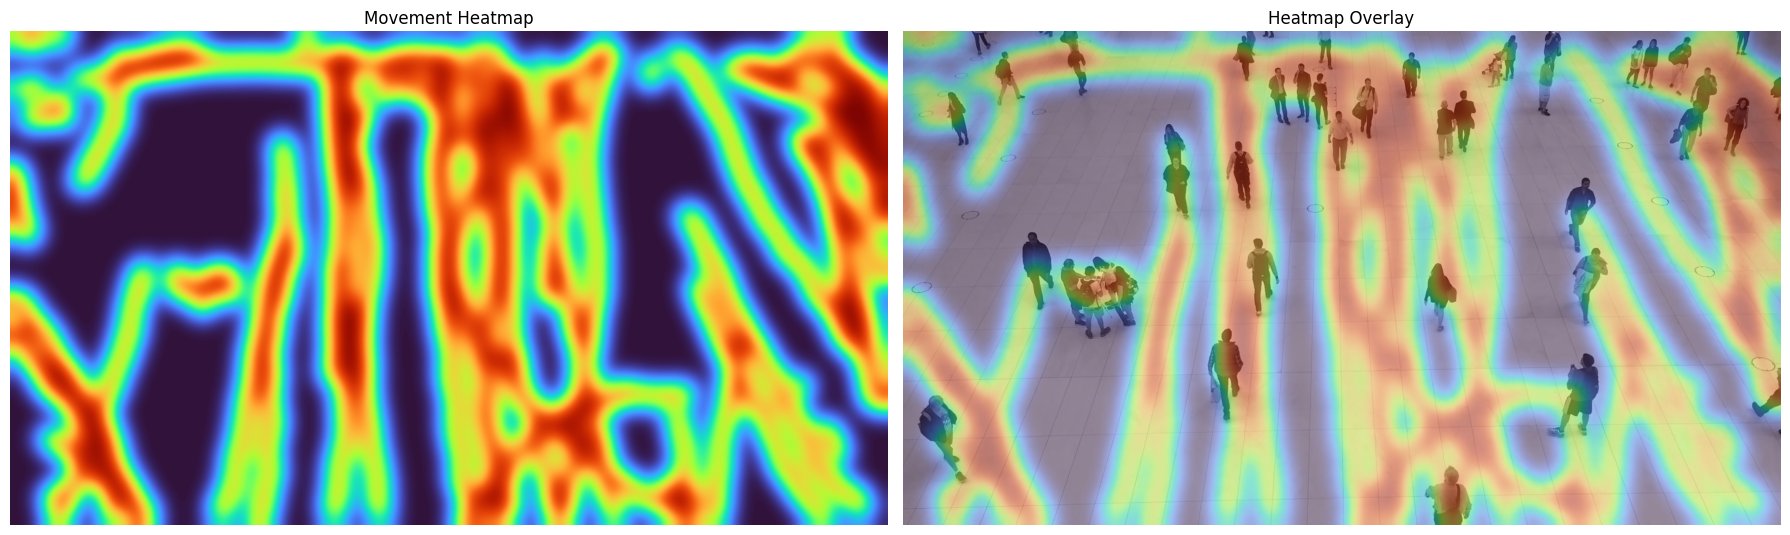

Heatmap overlay saved successfully!


In [ ]:
cap = cv2.VideoCapture(VIDEO_PATH)

ret, background = cap.read()

cap.release()

if ret:

    # Blend original frame and heatmap
    heatmap_overlay = cv2.addWeighted(
        background,
        0.55,
        colored_heatmap,
        0.45,
        0
    )

    # Save overlay
    cv2.imwrite(
        HEATMAP_OVERLAY_PATH,
        heatmap_overlay
    )

    # Display results
    plt.figure(figsize=(18, 8))

    plt.subplot(1, 2, 1)
    plt.imshow(
        cv2.cvtColor(colored_heatmap, cv2.COLOR_BGR2RGB)
    )
    plt.title("Movement Heatmap")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        cv2.cvtColor(heatmap_overlay, cv2.COLOR_BGR2RGB)
    )
    plt.title("Heatmap Overlay")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Heatmap overlay saved successfully!")

else:
    print("Unable to load original video frame.")

**Cell 18: People Flow Statistics**

In [ ]:
counting_df = pd.DataFrame(counting_events)

print("PEOPLE FLOW ANALYSIS")
print("=" * 40)

print("Total IN:", IN_COUNT)
print("Total OUT:", OUT_COUNT)
print("Total Counted:", IN_COUNT + OUT_COUNT)

if IN_COUNT + OUT_COUNT > 0:

    print(
        "IN Percentage:",
        round(IN_COUNT / (IN_COUNT + OUT_COUNT) * 100, 2),
        "%"
    )

    print(
        "OUT Percentage:",
        round(OUT_COUNT / (IN_COUNT + OUT_COUNT) * 100, 2),
        "%"
    )

print("\nCounting Event Details:")

display(counting_df)

PEOPLE FLOW ANALYSIS
Total IN: 12
Total OUT: 10
Total Counted: 22
IN Percentage: 54.55 %
OUT Percentage: 45.45 %

Counting Event Details:


,track_id,direction,frame
0,2,OUT,4
1,13,IN,13
2,30,OUT,17
3,5,OUT,61
4,9,IN,64
5,29,IN,66
6,22,IN,67
7,15,IN,74
8,23,IN,103
9,59,IN,107
